## 1. Installazione dipendenze

## 2. Import librerie

In [1]:
import os
import cv2
import numpy as np
import hdbscan
import math
import umap
import pickle
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from insightface.app import FaceAnalysis
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity



In [2]:
def assegna_periodo(filename):
    file_lower = filename.lower()
    
    if any(x in file_lower for x in ['i_musici', 'buona_ventura', 'maddalena-pentinente', 'ramarro', 'riposo-fuga']):
        return '1. Primo Periodo Romano'
    elif any(x in file_lower for x in ['giuditta', 'marta_e_maria', 'caterina_d_alessandria', 'fillide']):
        return '2. Periodo Grandi Patroni'
    elif any(x in file_lower for x in ['deposizione', 'morte_della_vergine', 'palafrenieri', 'loreto', 'san_matteo_e_angelo']):
        return '3. Maturità Romana'
    elif any(x in file_lower for x in ['golia', 'flagellazione', 'negazione', 'misericordia', 'rosario', 'nativita', 'salome', 'solome']):
        return '4. Periodo Esilio Tardo'
    # Gestione ambiguità (Cena in Emmaus e Incoronazione di spine)
    elif 'cena_in_emmaus' in file_lower:
        return '3. Maturità Romana'
    elif 'incoronazione_di_spine' in file_lower:
        return '3. Maturità Romana'
    else:
        return '5. Sconosciuto / Altro'

## 3. Caricamento modello ArcFace (InsightFace)
- **det_model**: RetinaFace per il rilevamento del volto
- **rec_model**: ArcFace ResNet50 per gli embedding (512-dim)


In [3]:
# ctx_id=0 usa GPU, ctx_id=-1 usa CPU
app = FaceAnalysis(
    name='buffalo_l',       # modello pesante: RetinaFace + ArcFace R100
    allowed_modules=['detection', 'recognition']
)
app.prepare(ctx_id=0, det_size=(640, 640)) #definizione input


Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Asus/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Asus/.insightface\models\buffalo_l\w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


## 4. Estrazione embedding da tutte le immagini

In [4]:
# 1. Definizione percorsi dataset
dataset_ia = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\generative_ia\dataset_caravaggio'
dataset_originali = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\originali\caravaggio'

all_embeddings = []
file_names = []
file_paths = []
source_types = [] 
skipped = []

valid_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.tif')

# 2. Lettura e aggregazione file
files_originali = [(f, dataset_originali, 'Originale') for f in os.listdir(dataset_originali) if f.lower().endswith(valid_extensions)]
files_ia = [(f, dataset_ia, 'IA') for f in os.listdir(dataset_ia) if f.lower().endswith(valid_extensions)]
all_files = files_originali + files_ia

print(f"Inizio lavoro su {len(all_files)} immagini totali ({len(files_originali)} originali e {len(files_ia)} da IA)...")

# 3. Modello di riconoscimento per fallback
rec_model = app.models.get('recognition', None)

# 4. Ciclo di estrazione embedding
for filename, folder_path, source_type in tqdm(all_files):
    try:
        full_path = os.path.join(folder_path, filename)
        img_bgr = cv2.imread(full_path)
        
        if img_bgr is None:
            raise ValueError("Immagine non leggibile con OpenCV")

        faces = app.get(img_bgr)

        if len(faces) == 0:
            # Fallback se il detector non rileva il volto nel ritaglio artistico
            img_resized = cv2.resize(img_bgr, (112, 112))
            img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
            img_input = (img_rgb.astype(np.float32) - 127.5) / 128.0
            img_input = np.transpose(img_input, (2, 0, 1))
            img_input = np.expand_dims(img_input, axis=0)
            
            feat = rec_model.get_feat(img_input).flatten()
            norm = np.linalg.norm(feat)
            embedding = feat / norm if norm > 0 else feat
        else:
            # Seleziona il volto principale (area bounding box maggiore)
            face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
            embedding = face.normed_embedding

        all_embeddings.append(embedding.flatten())
        file_names.append(filename)
        file_paths.append(full_path)
        source_types.append(source_type)

    except Exception as e:
        print(f"Errore su {filename}: {e}")
        skipped.append((filename, str(e)))

# 5. Creazione matrice e DataFrame
if len(all_embeddings) == 0:
    raise RuntimeError("Nessun embedding estratto. Verifica i percorsi delle immagini.")

X = np.array(all_embeddings)
print(f"\nMatrice embedding estratta: {X.shape[0]} immagini x {X.shape[1]} features")

df_metadata = pd.DataFrame({
    'file': file_names,
    'full_path': file_paths,
    'origine': source_types
})

# Assegnazione periodo stilistico
df_metadata['periodo'] = df_metadata['file'].apply(assegna_periodo)

if skipped:
    print(f"\nImmagini saltate ({len(skipped)}):")
    for s_file, s_err in skipped:
        print(f" - {s_file}: {s_err}")

Inizio lavoro su 85 immagini totali (25 originali e 60 da IA)...


  0%|          | 0/85 [00:00<?, ?it/s]

Errore su 160055_caravaggio.png: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:3789: error: (-215:Assertion failed) !dsize.empty() in function 'cv::hal::resize'


Matrice embedding estratta: 84 immagini x 512 features

Immagini saltate (1):
 - 160055_caravaggio.png: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:3789: error: (-215:Assertion failed) !dsize.empty() in function 'cv::hal::resize'



In [ ]:
# --- Impostazioni di supporto per le visualizzazioni ---

# Alias: df_style e' lo stesso DataFrame dei metadati (stessa riga/ordine di file_names e X_embedded)
df_style = df_metadata

# Palette colori per i periodi stilistici (una voce per ogni valore restituito da assegna_periodo)
colori_periodi = {
    '1. Primo Periodo Romano':   '#1f77b4',
    '2. Periodo Grandi Patroni': '#ff7f0e',
    '3. Maturit\u00e0 Romana':       '#2ca02c',
    '4. Periodo Esilio Tardo':   '#d62728',
    '5. Sconosciuto / Altro':    '#7f7f7f',
}

nome_test = "Unknown.tif"

if nome_test not in file_names:
    print(f"Attenzione: '{nome_test}' non e' presente tra i file analizzati. "
          f"Imposta 'nome_test' con un nome file valido per abilitare i confronti con l'immagine di riferimento.")

# Lookup rapido nome file -> percorso completo (utile nelle celle di visualizzazione dei cluster)
path_lookup = dict(zip(file_names, file_paths))


## 5. Riduzione dimensionale con UMAP

In [44]:
print("Avvio UMAP...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
X_embedded = reducer.fit_transform(X)
print("Riduzione UMAP completata.")

Avvio UMAP...
Riduzione UMAP completata.


c:\Users\Asus\miniconda3\envs\caravaggio\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


---
# BLOCCO A — HDBSCAN

## 6. Clustering HDBSCAN

In [45]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=2, min_samples=1, gen_min_span_tree=True,metric='euclidean') #metric='euclidean'
labels = clusterer.fit_predict(X_embedded)

results = pd.DataFrame({'file': file_names, 'cluster': labels})
print("\nRisultati HDBSCAN:")
print(results.sort_values(by='cluster').to_string())


Risultati HDBSCAN:
                                                file  cluster
32                             160036_caravaggio.png       -1
45                             160053_caravaggio.png       -1
46                             160054_caravaggio.png       -1
24                             160018_caravaggio.png       -1
21                             160013_caravaggio.png       -1
31                             160033_caravaggio.png       -1
3                        flagellazione_di_cristo.jpg        0
50                       flagellazione_di_cristo.jpg        0
1                   Davide_con_la_testa_di_golia.jpg        1
48                  Davide_con_la_testa_di_golia.jpg        1
11  Solome_con_la_testa_di_San_Giovanni_Battista.jpg        1
58  Solome_con_la_testa_di_San_Giovanni_Battista.jpg        2
54                    La_negazione_di_San_Pietro.jpg        2
7                     La_negazione_di_San_Pietro.jpg        2
22                             160016_caravaggio.p

## 7. Visualizzazione UMAP + HDBSCAN

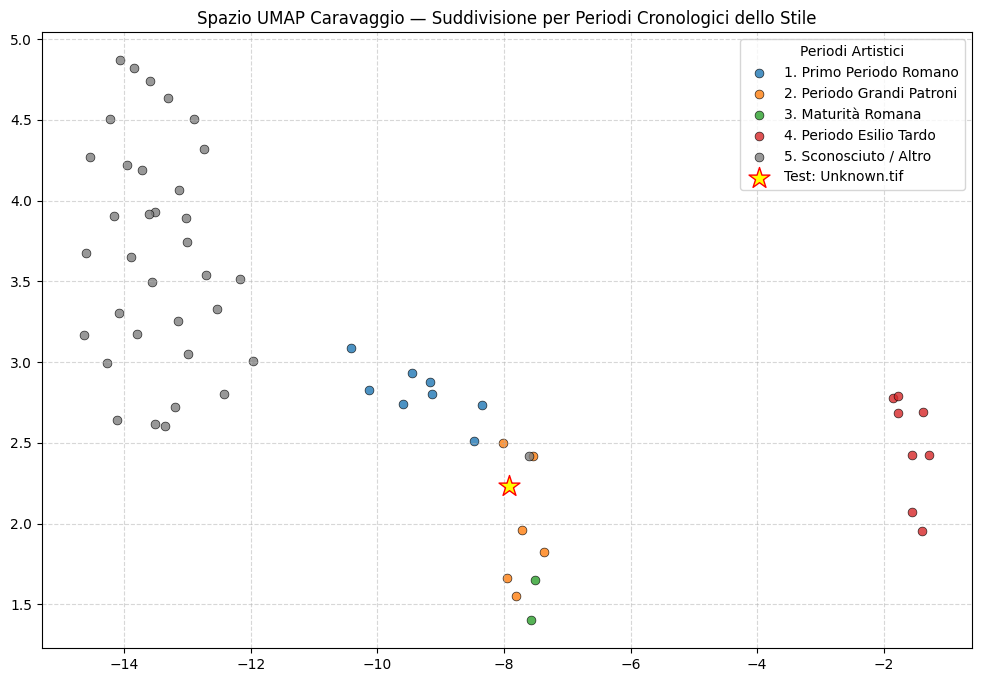

In [46]:
## 7. Visualizzazione UMAP — COLORATO PER STILE/PERIODO
plt.figure(figsize=(12, 8))

# Coloriamo i punti ciclando sui periodi così da avere una legenda testuale pulita
for periodo, colore in colori_periodi.items():
    id_periodo = df_style['periodo'] == periodo
    # Verifichiamo che ci siano effettivamente immagini di quel periodo estratte
    if np.sum(id_periodo) > 0:
        plt.scatter(
            X_embedded[id_periodo, 0], 
            X_embedded[id_periodo, 1],
            c=colore, 
            label=periodo, 
            s=40,          # Aumentato leggermente la dimensione per vederli meglio
            alpha=0.8, 
            edgecolors='k',# Aggiunge un bordino nero sottile attorno ai punti
            linewidths=0.5
        )

# Manteniamo la stella rossa per l'immagine di test
nome_test = "Unknown.tif"
if nome_test in file_names:
    idx_test = file_names.index(nome_test)
    plt.scatter(X_embedded[idx_test, 0], X_embedded[idx_test, 1],
                c='yellow', edgecolors='red', s=250, marker='*', zorder=5, label=f"Test: {nome_test}")

plt.legend(loc='upper right', title="Periodi Artistici")
plt.grid(True, linestyle='--', alpha=0.5)
plt.title(f'Spazio UMAP Caravaggio — Suddivisione per Periodi Cronologici dello Stile')
plt.show()

## 8. Analisi cluster immagine di test (HDBSCAN)


'Unknown.tif' -> Cluster HDBSCAN: 10
Cluster 10: 3 immagini.


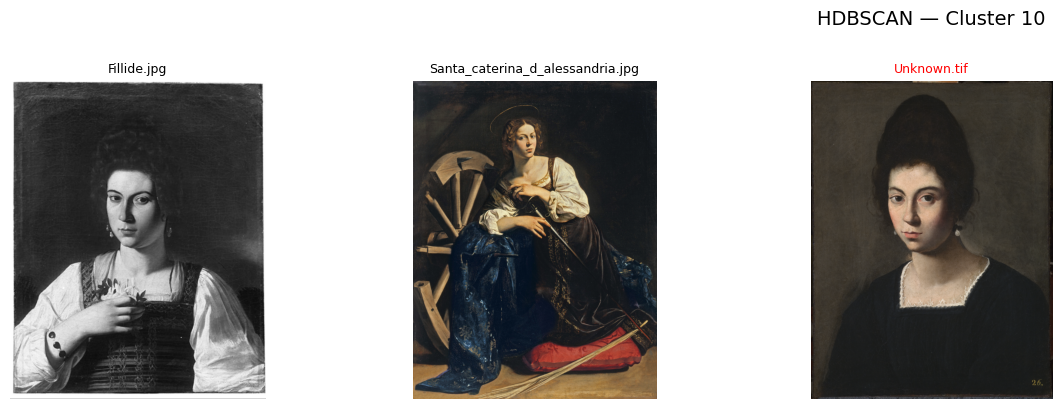


--- Similarita coseno HDBSCAN (Unknown.tif) ---
                        Immagine  Similarita Coseno
                     Fillide.jpg             0.4721
Santa_caterina_d_alessandria.jpg             0.3422
Media similarita: 0.4072


In [47]:
if nome_test in results['file'].values:
    cluster_id = results.loc[results['file'] == nome_test, 'cluster'].values[0]
    print(f"\n'{nome_test}' -> Cluster HDBSCAN: {cluster_id}")

    if cluster_id == -1:
        print("Classificata come RUMORE.")
    else:
        immagini_cluster = results[results['cluster'] == cluster_id]['file'].tolist()
        n_immagini = len(immagini_cluster)
        print(f"Cluster {cluster_id}: {n_immagini} immagini.")

        cols = 5
        rows = math.ceil(n_immagini / cols)
        plt.figure(figsize=(20, 4 * rows))
        for i, fn in enumerate(immagini_cluster):
            plt.subplot(rows, cols, i + 1)
            try:
                img_bgr = cv2.imread(path_lookup[fn])
                img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
                plt.imshow(img)
                color = 'red' if fn == nome_test else 'black'
                plt.title(fn, fontsize=9, color=color)
            except Exception as e:
                plt.title(f"Errore: {fn}", fontsize=8)
            plt.axis('off')
        plt.suptitle(f'HDBSCAN — Cluster {cluster_id}', fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()

        idx_test = file_names.index(nome_test)
        vettore_test = X[idx_test].reshape(1, -1)
        sim_results = []
        for fn in immagini_cluster:
            if fn == nome_test:
                continue
            idx_c = file_names.index(fn)
            sim = cosine_similarity(vettore_test, X[idx_c].reshape(1, -1))[0][0]
            sim_results.append({'Immagine': fn, 'Similarita Coseno': round(sim, 4)})

        df_sim = pd.DataFrame(sim_results).sort_values(by='Similarita Coseno', ascending=False)
        print(f"\n--- Similarita coseno HDBSCAN ({nome_test}) ---")
        print(df_sim.to_string(index=False) if not df_sim.empty else "Cluster con solo immagine test.")
        if not df_sim.empty:
            print(f"Media similarita: {df_sim['Similarita Coseno'].mean():.4f}")

---
# BLOCCO B — DBSCAN

## 9. K-Distance Plot per scegliere eps

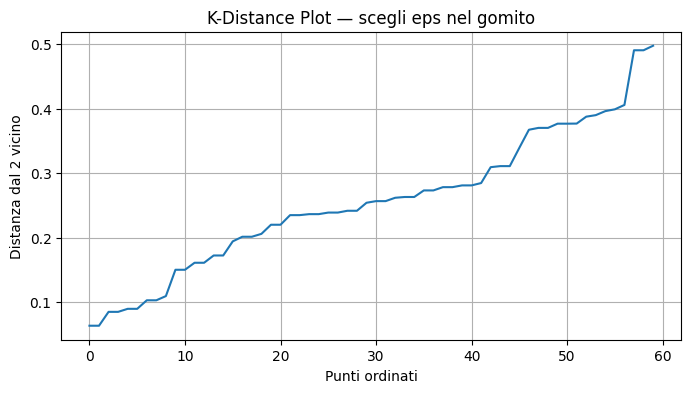

In [48]:
min_samples = 2
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_embedded)
distances, _ = neighbors.kneighbors(X_embedded)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Punti ordinati')
plt.ylabel(f'Distanza dal {min_samples} vicino')
plt.title('K-Distance Plot — scegli eps nel gomito')
plt.grid(True)
plt.show()

## 10. Clustering DBSCAN
> ⚠️ Modifica `eps` dopo aver osservato il gomito nel K-Distance Plot

In [49]:
eps = 0.55  # <-- modifica questo valore

clusterer_db = DBSCAN(eps=eps, min_samples=min_samples)
labels_db = clusterer_db.fit_predict(X_embedded)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = (labels_db == -1).sum()
print(f"\nDBSCAN — Cluster trovati: {n_clusters_db}  |  Punti rumore: {n_noise_db}")


DBSCAN — Cluster trovati: 4  |  Punti rumore: 0


## 11. Visualizzazione UMAP + DBSCAN

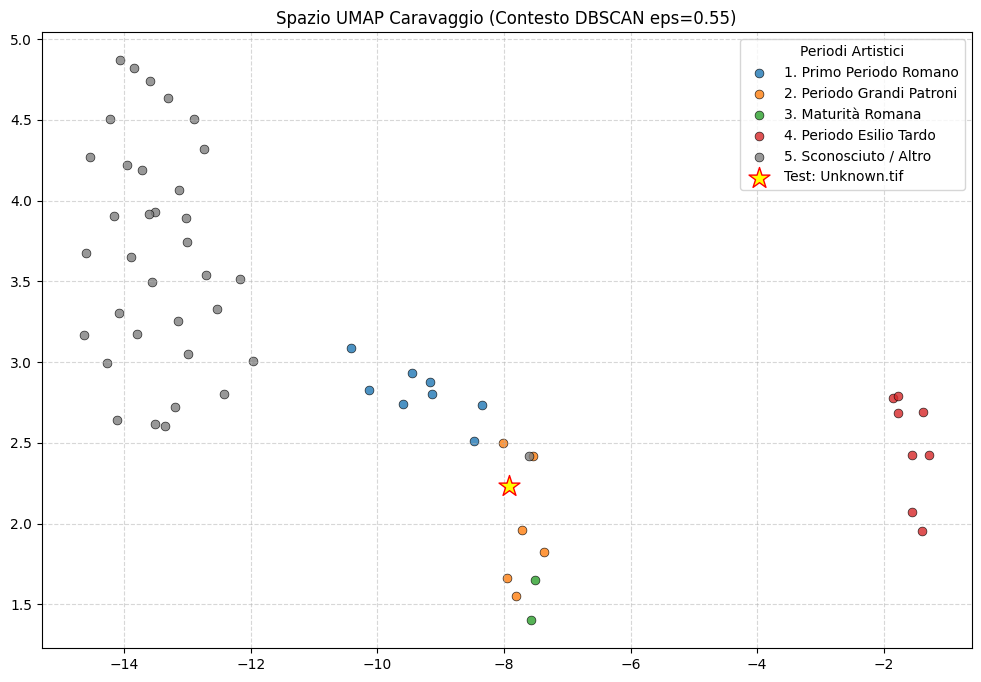

In [50]:
## 11. Visualizzazione UMAP (Replica per blocco DBSCAN)
plt.figure(figsize=(12, 8))

for periodo, colore in colori_periodi.items():
    id_periodo = df_style['periodo'] == periodo
    if np.sum(id_periodo) > 0:
        plt.scatter(X_embedded[id_periodo, 0], X_embedded[id_periodo, 1],
                    c=colore, label=periodo, s=40, alpha=0.8, edgecolors='k', linewidths=0.5)

if nome_test in file_names:
    idx_test = file_names.index(nome_test)
    plt.scatter(X_embedded[idx_test, 0], X_embedded[idx_test, 1],
                c='yellow', edgecolors='red', s=250, marker='*', zorder=5, label=f"Test: {nome_test}")

plt.legend(loc='upper right', title="Periodi Artistici")
plt.grid(True, linestyle='--', alpha=0.5)
plt.title(f'Spazio UMAP Caravaggio (Contesto DBSCAN eps={eps})')
plt.show()

## 12. Risultati DBSCAN

In [51]:
results_db = pd.DataFrame({'file': file_names, 'cluster': labels_db})
print(results_db.sort_values(by='cluster').to_string())

                                                file  cluster
0                                 Cena_in_Emmaus.jpg        0
57                  Santa_caterina_d_alessandria.jpg        0
53                              la_buona_ventura.jpg        0
51                           Giuditta_e_Olomerfe.png        0
49                                       Fillide.jpg        0
47                                Cena_in_Emmaus.jpg        0
12                                       Unknown.tif        0
10                  Santa_caterina_d_alessandria.jpg        0
59                                       Unknown.tif        0
6                               la_buona_ventura.jpg        0
2                                        Fillide.jpg        0
4                            Giuditta_e_Olomerfe.png        0
48                  Davide_con_la_testa_di_golia.jpg        1
7                     La_negazione_di_San_Pietro.jpg        1
11  Solome_con_la_testa_di_San_Giovanni_Battista.jpg        1
1       

## 13. Analisi cluster immagine di test (DBSCAN)


Cluster DBSCAN 0: 12 immagini.


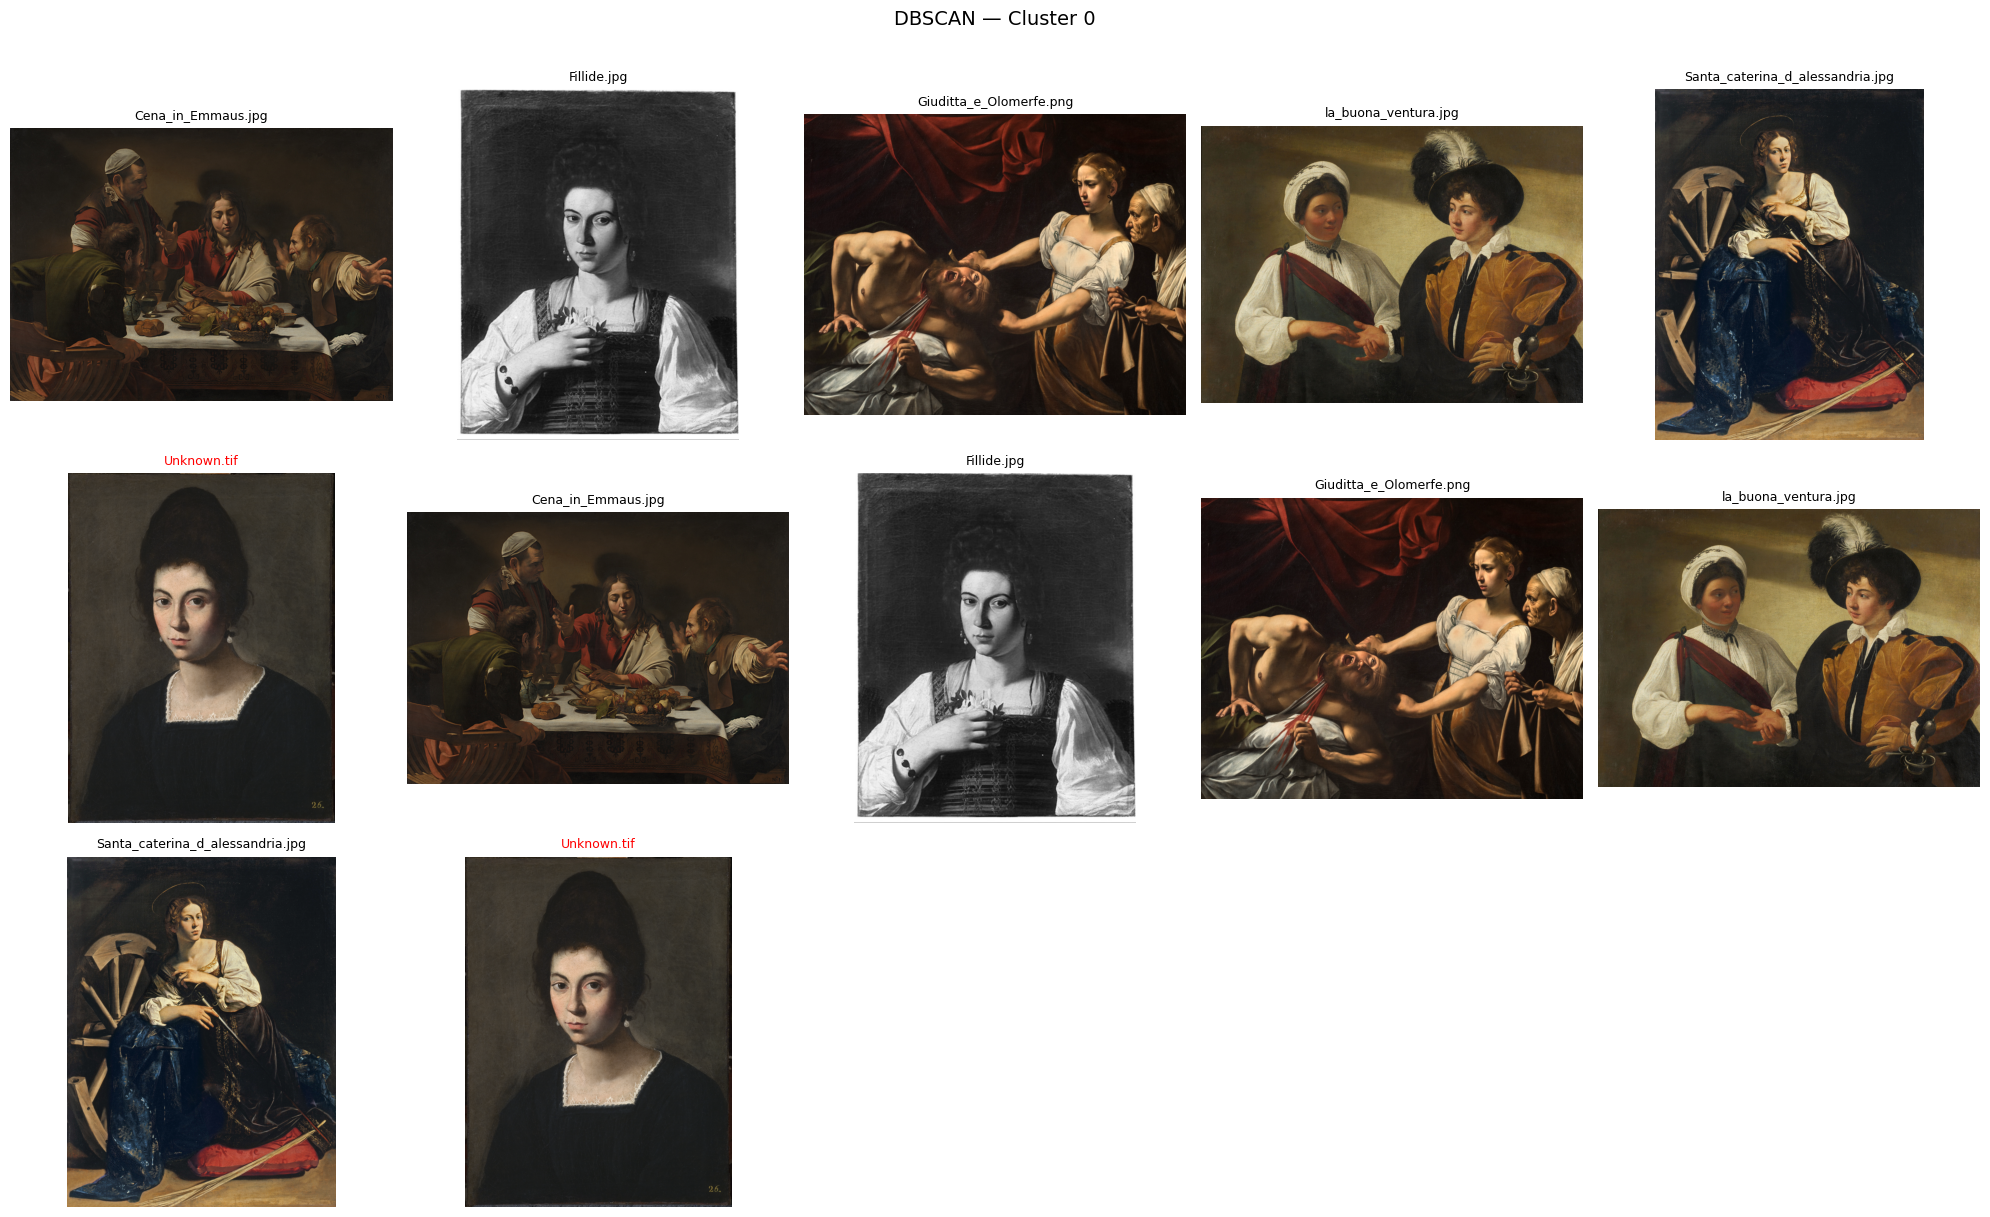


--- Similarita coseno DBSCAN (Unknown.tif) ---
                        Immagine  Similarita Coseno
                     Fillide.jpg             0.4721
                     Fillide.jpg             0.4721
Santa_caterina_d_alessandria.jpg             0.3422
Santa_caterina_d_alessandria.jpg             0.3422
            la_buona_ventura.jpg             0.2396
            la_buona_ventura.jpg             0.2396
         Giuditta_e_Olomerfe.png             0.1969
         Giuditta_e_Olomerfe.png             0.1969
              Cena_in_Emmaus.jpg             0.0919
              Cena_in_Emmaus.jpg             0.0919
Media similarita: 0.2685


In [52]:
if nome_test not in results_db['file'].values:
    print(f"File '{nome_test}' non trovato nel dataset.")
else:
    cluster_id_db = results_db.loc[results_db['file'] == nome_test, 'cluster'].values[0]

    if cluster_id_db == -1:
        print("Classificata come RUMORE. Prova ad abbassare eps o min_samples.")
    else:
        immagini_cluster_db = results_db[results_db['cluster'] == cluster_id_db]['file'].tolist()
        n_immagini = len(immagini_cluster_db)
        print(f"\nCluster DBSCAN {cluster_id_db}: {n_immagini} immagini.")

        cols = 5
        rows = math.ceil(n_immagini / cols)
        plt.figure(figsize=(20, 4 * rows))
        for i, fn in enumerate(immagini_cluster_db):
            plt.subplot(rows, cols, i + 1)
            try:
                img = mpimg.imread(path_lookup[fn])
                plt.imshow(img)
                color = 'red' if fn == nome_test else 'black'
                plt.title(fn, fontsize=9, color=color)
            except Exception as e:
                plt.title(f"Errore: {fn}", fontsize=8)
            plt.axis('off')
        plt.suptitle(f'DBSCAN — Cluster {cluster_id_db}', fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()

        idx_test = file_names.index(nome_test)
        vettore_test = X[idx_test].reshape(1, -1)
        sim_results_db = []
        for fn in immagini_cluster_db:
            if fn == nome_test:
                continue
            idx_c = file_names.index(fn)
            sim = cosine_similarity(vettore_test, X[idx_c].reshape(1, -1))[0][0]
            sim_results_db.append({'Immagine': fn, 'Similarita Coseno': round(sim, 4)})

        df_sim_db = pd.DataFrame(sim_results_db).sort_values(by='Similarita Coseno', ascending=False)
        print(f"\n--- Similarita coseno DBSCAN ({nome_test}) ---")
        print(df_sim_db.to_string(index=False) if not df_sim_db.empty else "Cluster con solo immagine test.")
        if not df_sim_db.empty:
            print(f"Media similarita: {df_sim_db['Similarita Coseno'].mean():.4f}")